# Video Game User Rating Prediction

## Project Overview

This project uses machine learning to predict user ratings for video games. The dataset contains game characteristics, review information, and user ratings.

The goal is to determine which game characteristics are associated with user ratings and evaluate how accurately machine learning models can predict those ratings.

## Research Questions

1. What factors are associated with higher user ratings?
2. Can machine learning predict a game's user rating?
3. Which features contribute most to the model's predictions?
4. Can review text improve rating predictions?

## Project Workflow

- Data loading and inspection
- Data cleaning
- Exploratory data analysis
- Feature engineering
- Train/test split
- Machine learning modeling
- Model evaluation
- Feature importance
- Model interpretation

In [79]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/jahnavipaliwal/video-game-reviews-and-ratings/video_game_reviews.csv


In [80]:
df = pd.read_csv(
    "/kaggle/input/datasets/jahnavipaliwal/video-game-reviews-and-ratings/video_game_reviews.csv"
)

df.head()

,Game Title,User Rating,Age Group Targeted,Price,Platform,Requires Special Device,Developer,Publisher,Release Year,Genre,Multiplayer,Game Length (Hours),Graphics Quality,Soundtrack Quality,Story Quality,User Review Text,Game Mode,Min Number of Players
0,Grand Theft Auto V,36.4,All Ages,41.41,PC,No,Game Freak,Innersloth,2015,Adventure,No,55.3,Medium,Average,Poor,"Solid game, but too many bugs.",Offline,1
1,The Sims 4,38.3,Adults,57.56,PC,No,Nintendo,Electronic Arts,2015,Shooter,Yes,34.6,Low,Poor,Poor,"Solid game, but too many bugs.",Offline,3
2,Minecraft,26.8,Teens,44.93,PC,Yes,Bungie,Capcom,2012,Adventure,Yes,13.9,Low,Good,Average,"Great game, but the graphics could be better.",Offline,5
3,Bioshock Infinite,38.4,All Ages,48.29,Mobile,Yes,Game Freak,Nintendo,2015,Sports,No,41.9,Medium,Good,Excellent,"Solid game, but the graphics could be better.",Online,4
4,Half-Life: Alyx,30.1,Adults,55.49,PlayStation,Yes,Game Freak,Epic Games,2022,RPG,Yes,13.2,High,Poor,Good,"Great game, but too many bugs.",Offline,1


In [81]:
df.shape

(47774, 18)

In [82]:
df.columns

Index(['Game Title', 'User Rating', 'Age Group Targeted', 'Price', 'Platform',
       'Requires Special Device', 'Developer', 'Publisher', 'Release Year',
       'Genre', 'Multiplayer', 'Game Length (Hours)', 'Graphics Quality',
       'Soundtrack Quality', 'Story Quality', 'User Review Text', 'Game Mode',
       'Min Number of Players'],
      dtype='object')

# Check data quality

In [83]:
df.isnull().sum()

Game Title                 0
User Rating                0
Age Group Targeted         0
Price                      0
Platform                   0
Requires Special Device    0
Developer                  0
Publisher                  0
Release Year               0
Genre                      0
Multiplayer                0
Game Length (Hours)        0
Graphics Quality           0
Soundtrack Quality         0
Story Quality              0
User Review Text           0
Game Mode                  0
Min Number of Players      0
dtype: int64

## Check the target variable

In [84]:
df["User Rating"].describe()   # check the target variable

count    47774.000000
mean        29.719329
std          7.550131
min         10.100000
25%         24.300000
50%         29.700000
75%         35.100000
max         49.500000
Name: User Rating, dtype: float64

In [85]:
df["User Rating"].head(10)        

0    36.4
1    38.3
2    26.8
3    38.4
4    30.1
5    38.6
6    33.1
7    32.3
8    26.7
9    23.9
Name: User Rating, dtype: float64

In [86]:
df[[
    "User Rating",
    "Price",
    "Game Length (Hours)"
]].corr()


print("Price R²:", df["Price"].corr(df["User Rating"]) ** 2)
print("Game Length R²:", df["Game Length (Hours)"].corr(df["User Rating"]) ** 2)

Price R²: 0.5786026615187051
Game Length R²: 0.395317763007488


In [87]:
df.dtypes

Game Title                  object
User Rating                float64
Age Group Targeted          object
Price                      float64
Platform                    object
Requires Special Device     object
Developer                   object
Publisher                   object
Release Year                 int64
Genre                       object
Multiplayer                 object
Game Length (Hours)        float64
Graphics Quality            object
Soundtrack Quality          object
Story Quality               object
User Review Text            object
Game Mode                   object
Min Number of Players        int64
dtype: object

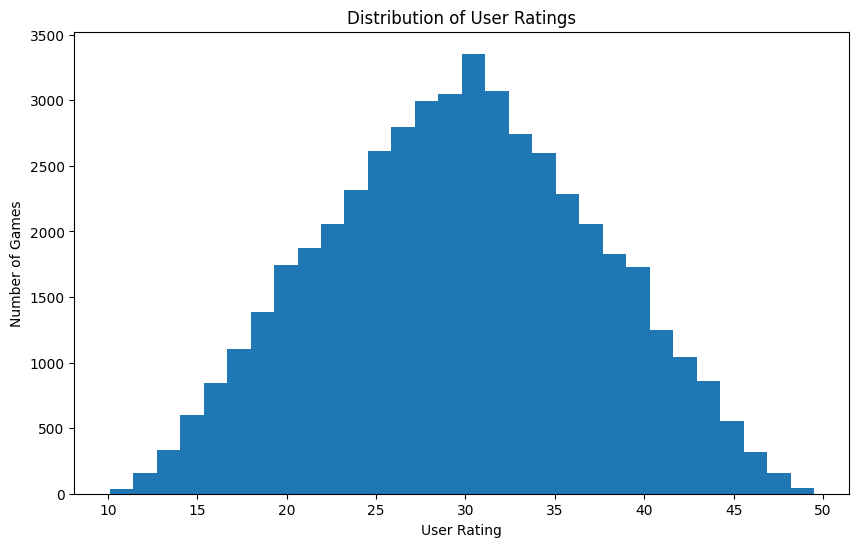

In [88]:
plt.figure(figsize=(10, 6))

plt.hist(df["User Rating"], bins=30)

plt.title("Distribution of User Ratings")
plt.xlabel("User Rating")
plt.ylabel("Number of Games")

plt.show()

### User Rating Distribution

The user ratings are approximately bell-shaped, with most ratings concentrated around 30. The ratings range from about 10 to 50, with relatively few games receiving ratings near either extreme.

In [89]:
features = [
    "Price",
    "Release Year",
    "Game Length (Hours)",
    "Min Number of Players",
    "Age Group Targeted",
    "Platform",
    "Requires Special Device",
    "Genre",
    "Multiplayer",
    "Graphics Quality",
    "Soundtrack Quality",
    "Story Quality",
    "Game Mode"
]

x = df[features]
y = df["User Rating"]

In [90]:
x.shape, y.shape

((47774, 13), (47774,))

In [91]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])         # split the data 80/20 split

Training rows: 38219
Testing rows: 9555


In [92]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = X.select_dtypes(include=["object"]).columns
numerical_features = X.select_dtypes(exclude=["object"]).columns

preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [93]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

linear_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  Index(['Price', 'Release Year', 'Game Length (Hours)',
       'Min Number of Players'],
      dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['Age Group Targeted', 'Platform', 'Requires Special Device', 'Genre',
       'Multiplayer', 'Graphics Quality', 'Soundtrack Quality',
       'Story Quality', 'Game Mode'],
      dtype='object'))])),
                ('model', LinearRegression())])

In [94]:
y_pred = linear_model.predict(X_test)

y_pred[:10]

array([20.36444666, 35.77660437, 28.62393531, 32.72675454, 32.19005905,
       28.73930469, 33.86850512, 26.30004047, 33.33765845, 33.87981185])

In [95]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 1.0009711101955936
RMSE: 1.157759702231619
R²: 0.9768515549953913


In [96]:
df[
    [
        "User Rating",
        "Price",                       # inspecting numerical variables
        "Release Year",
        "Game Length (Hours)",
        "Min Number of Players"
    ]
].corr()                                         

,User Rating,Price,Release Year,Game Length (Hours),Min Number of Players
User Rating,1.000000,0.760659,-0.003128,0.628743,-0.000365
Price,0.760659,1.000000,-0.005974,-0.002613,0.001908
Release Year,-0.003128,-0.005974,1.000000,0.002449,0.011940
Game Length (Hours),0.628743,-0.002613,0.002449,1.000000,-0.003122
Min Number of Players,-0.000365,0.001908,0.011940,-0.003122,1.000000


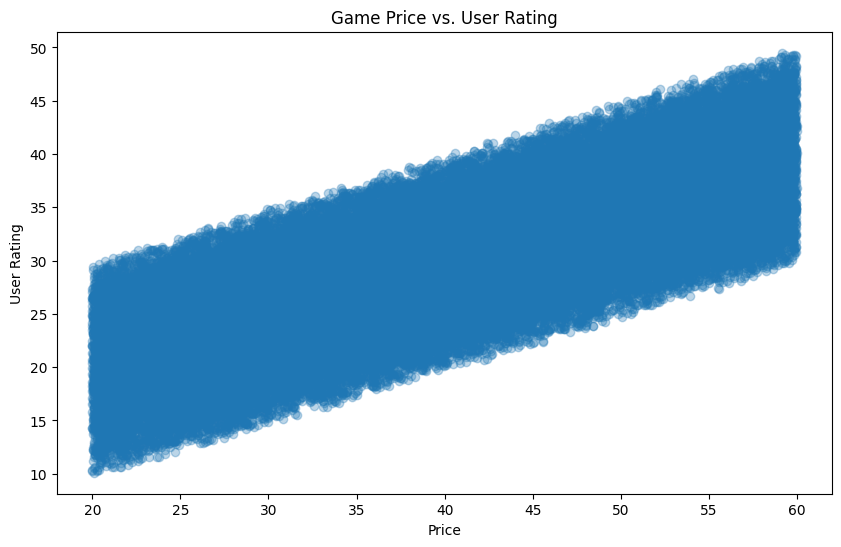

In [97]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Price"],
    df["User Rating"],
    alpha=0.3
)

plt.title("Game Price vs. User Rating")
plt.xlabel("Price")
plt.ylabel("User Rating")

plt.show()

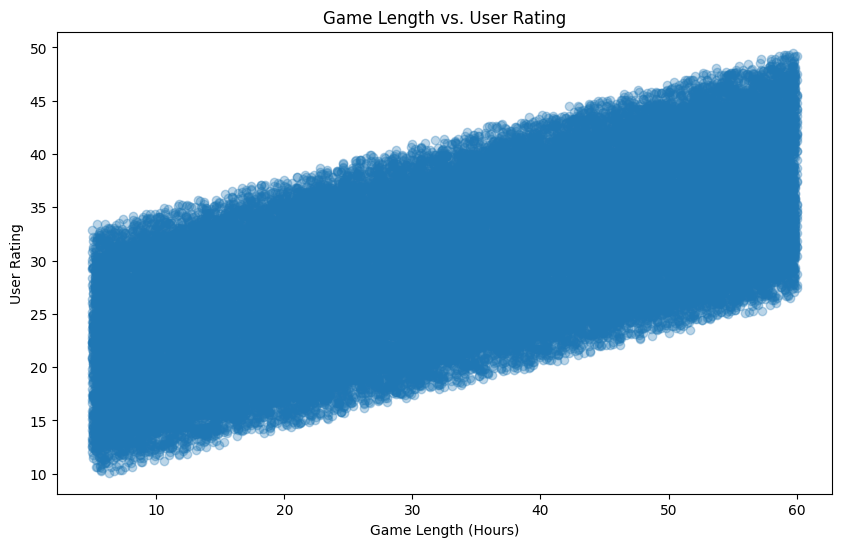

In [98]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Game Length (Hours)"],
    df["User Rating"],
    alpha=0.3
)

plt.title("Game Length vs. User Rating")
plt.xlabel("Game Length (Hours)")
plt.ylabel("User Rating")

plt.show()

## Random Forest Regression

Linear Regression provides a useful baseline, but it assumes a linear relationship between the features and the target. A Random Forest Regressor can capture more complex and nonlinear relationships.

The Random Forest model will be compared with the Linear Regression baseline using MAE, RMSE, and R².

In [99]:
from sklearn.ensemble import RandomForestRegressor

random_forest = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

random_forest.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  Index(['Price', 'Release Year', 'Game Length (Hours)',
       'Min Number of Players'],
      dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['Age Group Targeted', 'Platform', 'Requires Special Device', 'Genre',
       'Multiplayer', 'Graphics Quality', 'Soundtrack Quality',
       'Story Quality', 'Game Mode'],
      dtype='object'))])),
                ('model', RandomForestRegressor(n_jobs=-1, random_state=42))])

In [100]:
y_pred_rf = random_forest.predict(X_test)

rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
rf_r2 = r2_score(y_test, y_pred_rf)

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)
print("Random Forest R²:", rf_r2)

Random Forest MAE: 1.032758137100994
Random Forest RMSE: 1.212117218738486
Random Forest R²: 0.9746268605915388


## Model Comparison

The Random Forest model was compared with the Linear Regression baseline using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R².

Linear Regression achieved an MAE of approximately 1.001, an RMSE of approximately 1.158, and an R² of approximately 0.977. Random Forest achieved an MAE of approximately 1.033, an RMSE of approximately 1.212, and an R² of approximately 0.975.

In this dataset, Linear Regression performed slightly better than Random Forest across all three evaluation metrics. This suggests that the relationships between the selected features and User Rating are sufficiently structured that the more complex Random Forest model does not provide an improvement.

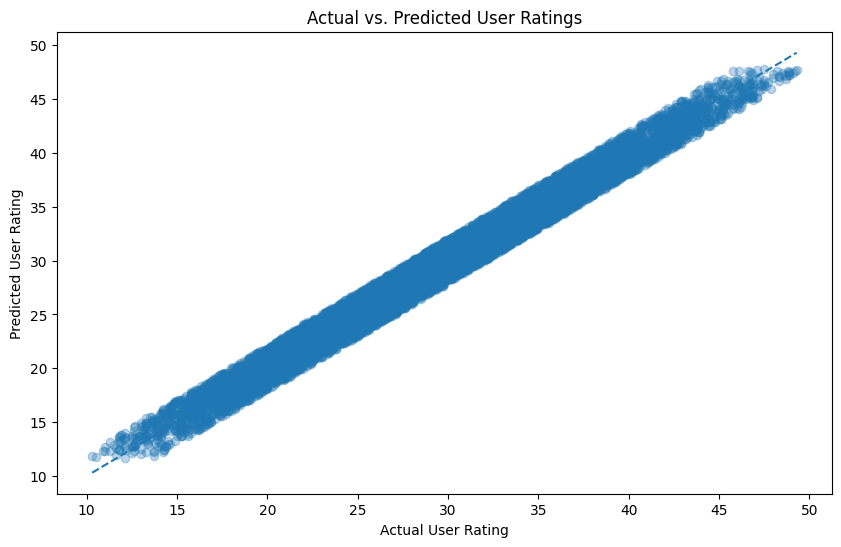

In [101]:
plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.3
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.title("Actual vs. Predicted User Ratings")
plt.xlabel("Actual User Rating")
plt.ylabel("Predicted User Rating")

plt.show()

## Actual vs. Predicted Ratings

The actual versus predicted plot shows that the model's predictions are closely aligned with the observed user ratings. Most points fall near the diagonal reference line, indicating relatively small prediction errors across much of the rating range.

The model performs well across both lower and higher ratings, although there is slightly more variation near the extreme values.

In [102]:
model_coefficients = pd.DataFrame({
    "Feature": ["Price", "Game Length (Hours)"],
    "Coefficient": simple_model.coef_
})

model_coefficients

,Feature,Coefficient
0,Price,0.499740
1,Game Length (Hours),0.299941


## Interpreting the Model Coefficients

The simplified Linear Regression model identified positive coefficients for both Price and Game Length.

The Price coefficient was approximately 0.500, meaning that a one-unit increase in price is associated with an estimated 0.50-point increase in User Rating, while holding Game Length constant.

The Game Length coefficient was approximately 0.300, meaning that a one-hour increase in game length is associated with an estimated 0.30-point increase in User Rating, while holding Price constant.

These relationships describe the patterns found within this dataset and should not be interpreted as evidence that increasing a game's price or length would directly cause higher ratings.

In [103]:
residuals = (
    df["User Rating"]
    - (0.5 * df["Price"] + 0.3 * df["Game Length (Hours)"])
)

residuals.describe()

count    47774.000000
mean        -0.000859
std          1.159238
min         -2.045000
25%         -1.010000
50%         -0.010000
75%          1.010000
max          2.045000
dtype: float64

## Residual Analysis

The residual analysis shows that the difference between the observed User Rating and the rating estimated from Price and Game Length is very small. The mean residual is approximately zero (-0.001), indicating that the simplified model does not have a substantial overall tendency to overpredict or underpredict ratings.

The residuals range from approximately -2.05 to 2.05, with a standard deviation of approximately 1.16. This helps explain why the simplified model achieved an R² of approximately 0.977.

The narrow residual range also suggests that User Rating may have been generated or strongly structured around Price and Game Length in this dataset. Therefore, the high model performance should be interpreted carefully and should not automatically be treated as evidence of real-world predictive power.

In [104]:
df["calculated_rating"] = (
    0.5 * df["Price"]
    + 0.3 * df["Game Length (Hours)"]
)

df[[
    "Price",
    "Game Length (Hours)",
    "User Rating",
    "calculated_rating"
]].head(10)

,Price,Game Length (Hours),User Rating,calculated_rating
0,41.41,55.3,36.4,37.295
1,57.56,34.6,38.3,39.160
2,44.93,13.9,26.8,26.635
3,48.29,41.9,38.4,36.715
4,55.49,13.2,30.1,31.705
5,51.73,48.8,38.6,40.505
6,46.44,36.9,33.1,34.290
7,36.92,52.1,32.3,34.090
8,22.20,56.4,26.7,28.020
9,20.09,46.0,23.9,23.845


## Investigating the Rating Formula

The calculated ratings are very close to the actual User Rating values when using Price and Game Length. This provides additional evidence that these two variables have a highly structured relationship with the target variable.

The simplified model's coefficients were approximately 0.500 for Price and 0.300 for Game Length. However, the calculated values are not identical to the actual ratings, meaning there is still some variation that is not explained by these two features.

Because the relationship is unusually strong, the model's high performance should be interpreted carefully. The dataset may contain a synthetic or highly structured relationship between Price, Game Length, and User Rating.

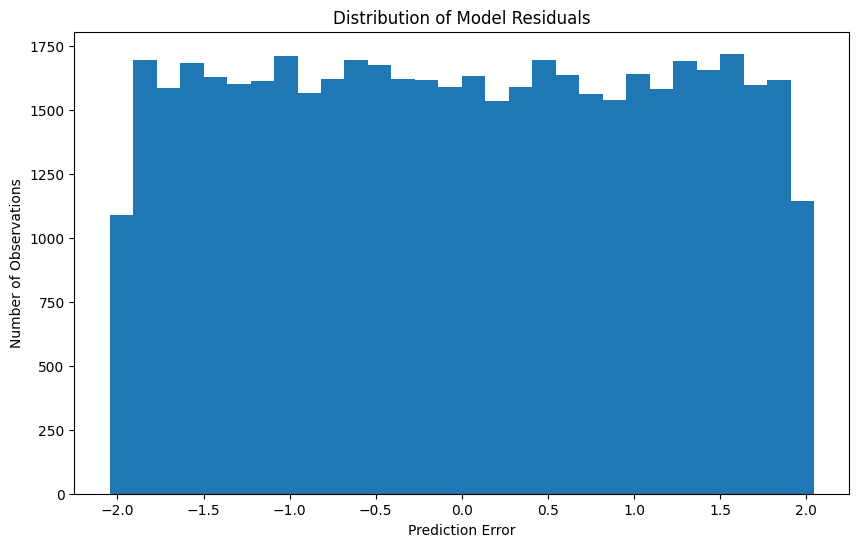

In [105]:
plt.figure(figsize=(10, 6))

plt.hist(residuals, bins=30)

plt.title("Distribution of Model Residuals")
plt.xlabel("Prediction Error")
plt.ylabel("Number of Observations")

plt.show()

## Residual Distribution

The residual histogram shows an approximately uniform distribution across the range of about -2.05 to 2.05. Rather than forming a bell-shaped distribution, the prediction errors are spread relatively evenly across the range.

This pattern, combined with the very high R² and the strong relationships between User Rating, Price, and Game Length, suggests that the dataset may contain a highly structured or synthetic relationship. This is an important limitation when interpreting the machine learning results.

In [106]:
print("Residual mean:", residuals.mean())
print("Residual standard deviation:", residuals.std())
print("Residual range:", residuals.min(), "to", residuals.max())

Residual mean: -0.0008585213714569144
Residual standard deviation: 1.1592384251870365
Residual range: -2.0450000000000017 to 2.0450000000000017


In [107]:
print(
    "Correlation between calculated rating and actual rating:",
    df["calculated_rating"].corr(df["User Rating"])
)

Correlation between calculated rating and actual rating: 0.9881427122247954


## Dataset Structure Finding

The calculated rating based on Price and Game Length had a Pearson correlation of approximately 0.988 with the actual User Rating. This is an extremely strong linear relationship.

Together with the simplified model's R² of approximately 0.977, the results indicate that Price and Game Length account for most of the variation in User Rating in this dataset.

This finding should be interpreted cautiously. The strength and structure of the relationship may indicate that the dataset was synthetically generated or that the rating variable was constructed using some of these features. Therefore, the model's high predictive performance should not be assumed to represent performance on real-world video game review data.

In [108]:
df[["Price", "Game Length (Hours)", "User Rating"]].sample(10, random_state=42)

,Price,Game Length (Hours),User Rating
20481,30.35,17.3,21.1
21278,56.70,25.0,35.8
37809,44.17,21.8,27.2
34452,32.23,55.4,34.1
35793,40.79,39.3,31.5
13019,42.24,25.4,29.8
20091,43.41,40.5,34.9
5762,41.31,18.8,26.2
4524,47.44,32.1,32.2
35961,44.40,38.9,35.8


## Data Investigation Summary

A random sample of observations continues to show a strong relationship between Price, Game Length, and User Rating. However, the calculated ratings are not identical to the observed ratings, indicating that additional variation remains in the target.

The analysis suggests that Price and Game Length contain most of the predictive information used by the models. Because the relationship is unusually strong, the dataset should be interpreted carefully. The available evidence is consistent with a highly structured dataset and may indicate synthetic data generation, but this cannot be confirmed from the analysis alone.

## Cross-Validation

A single train-test split can sometimes give a misleading estimate of model performance. To evaluate the stability of the Linear Regression model, five-fold cross-validation was used.

The dataset is divided into five parts. The model is trained on four parts and evaluated on the remaining part, repeating this process five times. The resulting scores provide a better estimate of how consistently the model performs on unseen data.

In [109]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    linear_model,
    X,
    y,
    cv=5,
    scoring="r2"
)

print("Cross-validation R² scores:", cv_scores)
print("Mean cross-validation R²:", cv_scores.mean())
print("Standard deviation:", cv_scores.std())

Cross-validation R² scores: [0.97613601 0.9764142  0.97683805 0.97612614 0.97641783]
Mean cross-validation R²: 0.9763864447253093
Standard deviation: 0.0002592988400087816


## Cross-Validation Results

Five-fold cross-validation produced R² scores ranging from approximately 0.9761 to 0.9768. The mean cross-validation R² was 0.9764, with a standard deviation of only 0.00026.

The small standard deviation indicates that the Linear Regression model performs consistently across different portions of the dataset. This supports the reliability of the evaluation results within this dataset.

However, the unusually high and stable performance should still be interpreted carefully because the exploratory analysis showed a very strong relationship between Price, Game Length, and User Rating.

In [110]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "RMSE": [rmse, rf_rmse],
    "R²": [r2, rf_r2]
})

comparison

,Model,MAE,RMSE,R²
0,Linear Regression,1.000971,1.157760,0.976852
1,Random Forest,1.032758,1.212117,0.974627


## Final Model Comparison

The two regression models produced very similar results. Linear Regression achieved an MAE of 1.001, an RMSE of 1.158, and an R² of 0.977. Random Forest achieved an MAE of 1.033, an RMSE of 1.212, and an R² of 0.975.

The results show that the more complex Random Forest model did not improve performance over the simpler Linear Regression model. This is consistent with the earlier analysis showing that Price and Game Length have strong relationships with User Rating.

The cross-validation results also showed that Linear Regression performed consistently across different subsets of the data, with a mean R² of 0.9764 and a very small standard deviation of 0.00026.

## Conclusion

This project used supervised machine learning to predict video game User Ratings from game characteristics such as Price, Game Length, Platform, Genre, and game features.

Linear Regression achieved an R² of approximately 0.977 with an MAE of approximately 1.001, while Random Forest achieved an R² of approximately 0.975 with an MAE of approximately 1.033. The simpler Linear Regression model therefore provided slightly better results on the test data.

Feature analysis showed that Price and Game Length contained most of the predictive information. A simplified model using only these two features achieved an R² of approximately 0.977, nearly matching the full model.

An important finding was the unusually strong relationship between Price, Game Length, and User Rating. The calculated rating based on these two variables had a correlation of approximately 0.988 with the actual rating. This suggests that the dataset contains a highly structured relationship and may have been synthetically generated, although this cannot be confirmed from the analysis alone.

Overall, the project demonstrates the complete machine learning workflow: data exploration, preprocessing, feature selection, model training, evaluation, comparison, cross-validation, and interpretation. The results also demonstrate why strong model performance should be investigated rather than accepted without examining the underlying data.

In [111]:
df.duplicated().sum()    # checking for duplicated rows

np.int64(0)

In [112]:
for col in [
    "Age Group Targeted",
    "Platform",
    "Requires Special Device",
    "Genre",
    "Multiplayer",
    "Graphics Quality",
    "Soundtrack Quality",
    "Story Quality",
    "Game Mode"
]:
    print(f"\n{col}:")
    print(df[col].nunique())


Age Group Targeted:
4

Platform:
5

Requires Special Device:
2

Genre:
10

Multiplayer:
2

Graphics Quality:
4

Soundtrack Quality:
4

Story Quality:
4

Game Mode:
2


In [113]:
for col in [
    "Graphics Quality",
    "Soundtrack Quality",
    "Story Quality"
]:
    print(f"\n{col}")
    print(
        df.groupby(col)["User Rating"]
        .mean()
        .sort_values(ascending=False)
    )


Graphics Quality
Graphics Quality
High      29.808140
Ultra     29.757091
Medium    29.711080
Low       29.598882
Name: User Rating, dtype: float64

Soundtrack Quality
Soundtrack Quality
Good         29.774351
Excellent    29.767788
Poor         29.739209
Average      29.595725
Name: User Rating, dtype: float64

Story Quality
Story Quality
Excellent    29.809102
Poor         29.735221
Average      29.695956
Good         29.635715
Name: User Rating, dtype: float64


In [114]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    linear_model,
    X_test,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring="r2"
)

importance = pd.Series(
    perm.importances_mean,
    index=X_test.columns
).sort_values(ascending=False)

importance

Price                      1.155454e+00
Game Length (Hours)        7.818730e-01
Multiplayer                4.161709e-06
Game Mode                  7.708639e-07
Min Number of Players      4.329648e-07
Story Quality             -2.850449e-06
Requires Special Device   -3.156563e-06
Soundtrack Quality        -3.995210e-06
Graphics Quality          -5.903948e-06
Age Group Targeted        -6.334132e-06
Release Year              -6.346539e-06
Platform                  -8.816464e-06
Genre                     -1.851766e-05
dtype: float64

In [115]:
X_simple = df[
    ["Price", "Game Length (Hours)"]
]

X_train_simple, X_test_simple, y_train_simple, y_test_simple = train_test_split(
    X_simple,
    y,
    test_size=0.20,
    random_state=42
)


In [116]:
simple_model = LinearRegression()

simple_model.fit(
    X_train_simple,
    y_train_simple
)

simple_pred = simple_model.predict(X_test_simple)

simple_r2 = r2_score(
    y_test_simple,
    simple_pred
)

simple_mae = mean_absolute_error(
    y_test_simple,
    simple_pred
)

print("Simple Model R²:", simple_r2)
print("Simple Model MAE:", simple_mae)

Simple Model R²: 0.9769164926233966
Simple Model MAE: 0.9992664110663592


## Investigating Strong Feature Relationships

The simplified model produced nearly the same performance as the full model. Because this result is unusually strong, the next step is to examine the distributions and relationships among Price, Game Length, and User Rating.

This helps determine whether the high predictive performance reflects meaningful patterns in the data or potentially artificial relationships within the dataset.

In [117]:
print(df[[
    "Price",
    "Game Length (Hours)",
    "User Rating"
]].describe())

              Price  Game Length (Hours)   User Rating
count  47774.000000         47774.000000  47774.000000
mean      39.951371            32.481672     29.719329
std       11.520342            15.872508      7.550131
min       19.990000             5.000000     10.100000
25%       29.990000            18.800000     24.300000
50%       39.845000            32.500000     29.700000
75%       49.957500            46.300000     35.100000
max       59.990000            60.000000     49.500000


In [118]:
print(
    df[
        ["Price", "Game Length (Hours)", "User Rating"]
    ].corr()
)

                        Price  Game Length (Hours)  User Rating
Price                1.000000            -0.002613     0.760659
Game Length (Hours) -0.002613             1.000000     0.628743
User Rating          0.760659             0.628743     1.000000


### Correlation Findings

Price has a strong positive correlation with User Rating (r = 0.761), while Game Length has a moderately strong positive correlation with User Rating (r = 0.629). This indicates that higher-priced and longer games tend to have higher user ratings within this dataset.

Price and Game Length have almost no correlation with each other (r = -0.003), suggesting that these two features provide largely independent information when predicting User Rating.

The strength of these relationships helps explain why a model using only Price and Game Length performed nearly as well as the full feature set.

# Final Project Summary

## Objective

The goal of this project was to use supervised machine learning to predict video game User Ratings based on characteristics such as Price, Game Length, Platform, Genre, and other game features.

## Models

Two regression models were evaluated:

- Linear Regression
- Random Forest Regression

## Results

Linear Regression achieved an MAE of approximately 1.001, an RMSE of approximately 1.158, and an R² of approximately 0.977.

Random Forest achieved an MAE of approximately 1.033, an RMSE of approximately 1.212, and an R² of approximately 0.975.

Five-fold cross-validation produced a mean R² of approximately 0.976, showing that the Linear Regression results were consistent across different portions of the dataset.

## Key Findings

Price and Game Length were the strongest predictors of User Rating. A simplified model using only these two variables achieved an R² of approximately 0.977, nearly matching the full model.

The analysis also found a very strong correlation between a calculated rating based on Price and Game Length and the actual User Rating. This suggests that the dataset contains a highly structured relationship between these variables.

## Limitations

The unusually strong predictive performance should be interpreted carefully. The analysis suggests that the dataset may contain a synthetic or highly structured relationship, although this cannot be confirmed from the analysis alone.

The relationships identified in this project are associations within the dataset and should not be interpreted as evidence that changing a game's price or length would directly cause its rating to change.

## Conclusion

This project demonstrates a complete supervised machine learning workflow, including data exploration, preprocessing, feature analysis, model training, evaluation, model comparison, residual analysis, and cross-validation.

The results also demonstrate the importance of investigating unusually strong model performance and understanding the structure and limitations of a dataset rather than relying only on evaluation metrics.